# Visual browser element locator
Recipe 77 · Level 3 · Intermediate · `Box` + `Noul` + image

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S10: [Box](https://docs.typesafe.ai/primitives/box)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14](https://typesafe.ai/blog/jev-1-14)

## What you will build

Locate a named button, form input, or menu item in a screenshot before recording a **simulated** browser action. Jev supplies narrow visual judgments; Python owns every permission to proceed, coordinate conversion, and simulated action. The screenshots are original drawings of a fictional project workspace.

`Box` yields one normalized rectangle, including when its target is absent. We first ask three `Noul` propositions about presence, uniqueness and enabled state, then ask for a rectangle only when those judgments pass. A high Box confidence alone cannot establish that the target exists. A screenshot also cannot prove the current live page is unchanged, so this recipe connects to no browser.

A [confidence gate](../../docs/glossary.md#confidence-gate) is a Python rule that requires sufficient certainty before accepting a result. Here presence uses Noul's probability directly, while localization uses Box's own confidence. [Review](../../docs/glossary.md#review) means a person must decide; it never executes an action. These distinctions follow [S02 — primitives](https://docs.typesafe.ai/primitives), [S03 — confidence](https://docs.typesafe.ai/confidence), and [S10 — Box](https://docs.typesafe.ai/primitives/box).

## Setup and run mode

The committed run replays synthetic answers written for the recipe. All numbers in that mode check the pipeline and say nothing about Jev quality. The 10 validation and 12 test screenshots are scored separately; two demonstrations are unscored. Images live in `assets/`, outside the JSON-only `fixtures/` folder.

Live inference is optional: install the repository's live dependencies and set `JEV_COOKBOOK_LIVE=1`, `JEV_COOKBOOK_LIVE_MODEL=jev-1.14.0`, `TYPESAFE_API_KEY`, and a deliberate request budget such as `JEV_COOKBOOK_LIVE_MAX_REQUESTS=60`. `images=True` enables the experimental images header. `jev-1.14.0` is pinned because Box needs that model generation; aliases can move. See [S09 — images](https://docs.typesafe.ai/images), [S11 — models](https://docs.typesafe.ai/models), [S12 — Jev 1.14](https://typesafe.ai/blog/jev-1-14), and [offline and live](../../docs/offline-and-live.md). The notebook executor always runs offline.

In [1]:
import json
from pathlib import Path

from matplotlib.figure import Figure
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, run_header, show_answer
from jev_cookbook.vision import draw_boxes

apply_style()
recipe_dir = Path.cwd()
helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
scored = [e for e in examples if e.split != "demo"]
run_header(77, "Visual browser element locator", backend=backend, n_examples=len(scored))
check = " (pipeline check, not a Jev result)" if backend.mode in ("synthetic", "scripted") else ""
selection = " (selection step, not a result)"
reportable = backend.mode != "live"
record_note = (
    f" (recorded {backend.model}; dates {', '.join(backend.recorded_dates)})"
    if backend.mode == "recorded"
    else ""
)

Recipe 77: Visual browser element locator
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 22 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state contains a target name, its control kind and an opaque image reference derived from the PNG bytes. The corresponding asset carries the pixels in the official raw image format. No filename hint, gold coordinate, enabled flag, or presence label enters the request. Each screenshot is 512 × 384 pixels, within the image API's dimension and area limits.

A [gold label](../../docs/glossary.md#gold-label) is the authored answer used to check a prediction. Presence, uniqueness, enabled state and all matching rectangles live separately in `labels.jsonl`; duplicated controls have two gold rectangles. The generator knows the drawing geometry, but inference sees only the rendered screenshot.

The same fictional application and two layout families recur across splits. The split prevents threshold selection on test answers; it does not demonstrate generalization to unseen applications or templates.

In [2]:
demo = select_split(examples, "demo")[0]
state, assets = helpers.request_data(demo.fields, recipe_dir)
print(json.dumps(state, indent=2))
print("Image dimensions:", helpers.dimensions(demo.fields, recipe_dir))
print(
    "Asset type and format:",
    next(iter(assets.values()))["type"],
    next(iter(assets.values()))["format"],
)

{
  "screenshot": "image:sha256:4c938206e443e9077582b00b76558e68ba2c90595ef7e100e0af868c1b4c9b1c",
  "target": "Save changes",
  "kind": "button"
}
Image dimensions: (512, 384)
Asset type and format: image png


## The questions

The first request batches three independent statements. Their answers are probabilities of truth, not a separate Noul confidence field. Python requires each probability to meet or exceed the selected presence threshold. A sufficiently low presence probability yields a final absent answer with no action; the uncertain middle goes to review.

Only an eligible target receives the dependent Box request. One Box cannot represent several matching controls, so low uniqueness routes to review rather than picking a duplicate. The enabled-state proposition is also required: localizing a greyed-out button does not authorize a click. Box edges are fractions measured from the image's top-left; Python validates their range and ordering before producing pixel coordinates.

In [3]:
for name, question in helpers.build_questions().items():
    print(name, json.dumps(question.to_dict()))
print("Dependent request:", json.dumps(helpers.box_questions()["target_box"].to_dict()))

present {"type": "noul", "instructions": "The screenshot visibly contains the named target control.", "criteria": null}
unique {"type": "noul", "instructions": "Exactly one visible control matches the target name and kind; there is no second equally plausible matching control.", "criteria": null}
enabled {"type": "noul", "instructions": "The named target control is visibly enabled for interaction, rather than greyed out, disabled, or covered.", "criteria": null}
Dependent request: {"type": "box", "instructions": "Locate the single named target control in the screenshot. Return its complete outer rectangle, excluding its surrounding card and excluding any separate text label above an input."}


## One answer up close

Start with one unscored demonstration using illustrative thresholds of 0.90. These settings do not select the test policy; validation does that below. The printed typed answers precede the screenshot overlay and crop, so the proposed coordinates remain inspectable independently of the visualization.

present
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
unique
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
enabled
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Box: normalized coordinates (confidence 0.97)
  top=0.62, bottom=0.72, left=0.13, right=0.44
Provenance: synthetic
Decision: located - all gates passed
Proposed pixel center: (146, 257)


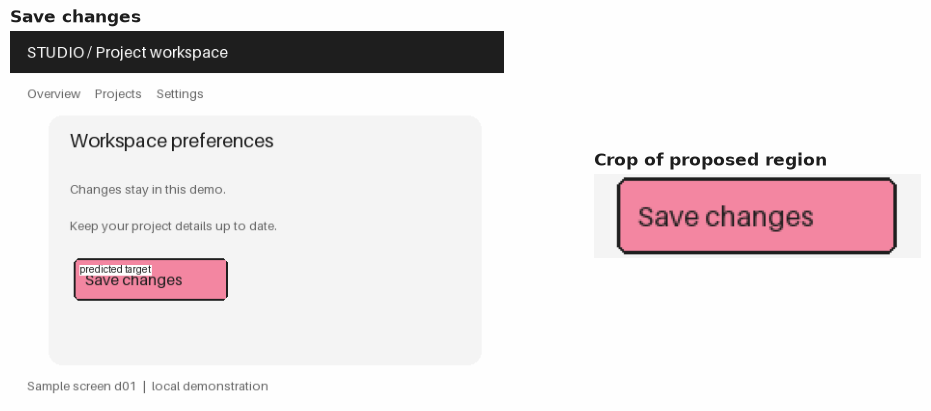

In [4]:
demo_policy = helpers.Policy(presence=0.90, box=0.90)
demo_observation = helpers.observe(backend, demo.fields, recipe_dir, demo_policy.presence)
for name, answer in demo_observation.judgments.items():
    print(name)
    show_answer(answer)
if demo_observation.location is not None:
    show_answer(demo_observation.location)
demo_outcome = helpers.route(
    demo_observation, demo_policy, helpers.dimensions(demo.fields, recipe_dir)
)
print("Decision:", demo_outcome.status, "-", demo_outcome.reason)
print("Proposed pixel center:", demo_outcome.point)
helpers.show_location(demo.fields, recipe_dir, demo_outcome)

## Python's part

`route` rechecks every first-stage gate even if it is handed a high-confidence rectangle. Missing Box confidence always enters review; Python never substitutes zero or one. Invalid, nonfinite, reversed, empty, or out-of-image rectangles are refused rather than clamped into a plausible click. Valid normalized edges become a bounded pixel center using the actual image dimensions.

`ActionLog` records a simulated click for a button/menu or a simulated focus for an input, with `executed=False`. `ReviewQueue` records unresolved judgments. A confident absent answer writes neither: it means nothing matched, so nothing happened. This [simulation](../../docs/simulation.md) preserves all answer evidence without invoking a browser.

In [5]:
demo_outcome, demo_actions, demo_reviews = helpers.simulate(
    demo, demo_observation, demo_policy, recipe_dir
)
print("SIMULATED actions:")
for action in demo_actions.to_dicts():
    print(json.dumps({key: action[key] for key in ("kind", "payload", "executed", "rule")}))
print("Review reasons:", [item["reason"] for item in demo_reviews.to_dicts()])

SIMULATED actions:
{"kind": "simulate_click", "payload": {"example": "d01", "target": "Save changes", "point": [146, 257]}, "executed": false, "rule": "presence + unique + enabled + box confidence + bounds"}
Review reasons: []


### A rectangle when nothing matches

The second demonstration asks for “Export CSV”, but the screenshot contains “Import CSV”. The normal first gate stops after the presence judgments. We then make one **explicitly ungated counterfactual request**, solely to expose the Box failure mode: synthetic Box returns an unrelated rectangle at 0.99 confidence despite absence. Passing that rectangle back through the policy still cannot create an action. This extra request is not part of the deployed two-stage rule or either evaluation split.

Noul: 0.01 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Ungated counterfactual:
Box: normalized coordinates (confidence 0.99)
  top=0.24, bottom=0.32, left=0.11, right=0.55
Provenance: synthetic
Gated decision: absent - target judged absent
SIMULATED action log: []


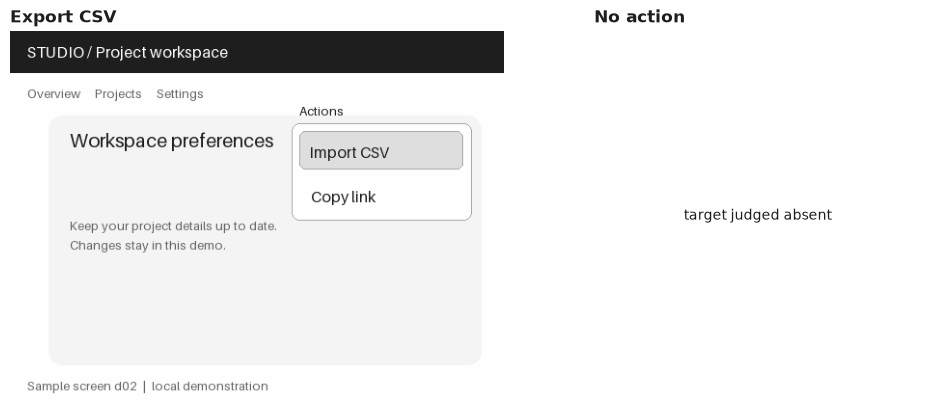

In [6]:
absent_demo = select_split(examples, "demo")[1]
absent_observation = helpers.observe(backend, absent_demo.fields, recipe_dir, demo_policy.presence)
show_answer(absent_observation.judgments["present"])
absent_state, absent_assets = helpers.request_data(absent_demo.fields, recipe_dir)
counterfactual_box = backend.decide(absent_state, helpers.box_questions(), assets=absent_assets)[
    "target_box"
]
print("Ungated counterfactual:")
show_answer(counterfactual_box)
with_box = helpers.Observation(absent_observation.judgments, counterfactual_box)
absent_outcome, absent_actions, absent_reviews = helpers.simulate(
    absent_demo, with_box, demo_policy, recipe_dir
)
print("Gated decision:", absent_outcome.status, "-", absent_outcome.reason)
print("SIMULATED action log:", absent_actions.to_dicts())
helpers.show_location(absent_demo.fields, recipe_dir, absent_outcome)

## Evaluation

Validation selects the presence and Box thresholds from a fixed grid, then freezes both before test is opened. For validation only, observations are collected under the least restrictive candidate presence gate; the cached answers can then be evaluated under stricter gates without extra calls. No Box is requested when even that first gate fails.

The declared selection objective maximizes whole-task success, then minimizes incorrect simulated actions, then chooses stricter thresholds on ties. Whole-task success requires an adequate rectangle for an enabled unique target, an absent decision for an absent target, and a review decision for a disabled or duplicate target. A missed eligible target is a failure, even if review was prudent. This tradeoff is part of the objective, rather than a quality claim about synthetic responses.

Intersection-over-union (IoU) is the overlap area divided by the union area, computed in Python. Localization succeeds at IoU ≥ 0.50. Mean IoU includes every enabled unique positive, with zero for missing predictions. We also count false localizations on absent targets, using all absent examples as their denominator. These separate denominators prevent a present-only localization score from hiding absence failures.

[Coverage](../../docs/glossary.md#coverage) is the fraction receiving a final answer (a location or confident absence); [risk](../../docs/glossary.md#risk) is the error fraction among those answered cases. Review is abstention. `evaluate_outcomes` uses actual policy outcomes, so duplicate, disabled and missing-confidence refusals remain in N. No fallback confidence exemption is needed: confident absence passes its own probability gate.

`missed_actionable` counts eligible targets for which no rectangle was accepted. A wrong accepted rectangle increments `unsafe_actions` instead and still fails localization success; these are distinct failure modes.

In [7]:
validation = select_split(examples, "validation")
validation_observations = {
    e.id: helpers.observe(backend, e.fields, recipe_dir, min(helpers.PRESENCE_CANDIDATES))
    for e in validation
}
policy, sweep = helpers.select_policy(
    validation,
    validation_observations,
    labels,
    recipe_dir,
    objective="task_success_then_fewer_unsafe_actions",
)
print(f"Validation N={len(validation)}{selection}{check}{record_note}")
for row in sweep:
    values = {
        key: round(row[key], 3)
        for key in ("presence", "box", "task_success", "unsafe_actions", "abstention")
    }
    print(f"N={len(validation)} {values}{selection}{check}{record_note}")
print(
    f"Frozen policy: presence={policy.presence:.2f}, Box={policy.box:.2f}; N={len(validation)}{selection}{check}{record_note}"
)

Validation N=10 (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.8, 'box': 0.8, 'task_success': 0.6, 'unsafe_actions': 2, 'abstention': 0.4} (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.8, 'box': 0.9, 'task_success': 0.6, 'unsafe_actions': 1, 'abstention': 0.5} (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.8, 'box': 0.95, 'task_success': 0.5, 'unsafe_actions': 1, 'abstention': 0.6} (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.9, 'box': 0.8, 'task_success': 0.6, 'unsafe_actions': 1, 'abstention': 0.5} (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.9, 'box': 0.9, 'task_success': 0.6, 'unsafe_actions': 0, 'abstention': 0.6} (selection step, not a result) (pipeline check, not a Jev result)
N=10 {'presence': 0.9, 'box': 0.95, 'task_success': 0.5, 'unsafe_actions': 0, 'abstention': 0.7} (selection

### Freeze, then compare with a known-layout baseline

The baseline uses one fixed rectangle per control kind from the original desktop layout. It reads no gold annotations and performs no image interpretation. It always proposes a location, including when the target is absent or disabled. Reflow moves controls away from those hard-coded positions. This is a useful failure-oriented baseline, not a modern browser locator benchmark.

The test split is evaluated once with the frozen policy. The report includes all test screenshots, including three absent targets, one duplicate pair, one disabled menu item and an accepted wrong rectangle. Confidence can be wrong: the gates lower some risks but cannot prove that the pixels were interpreted correctly.

In [8]:
test = select_split(examples, "test")
actions, reviews = ActionLog(), ReviewQueue()
test_observations, outcomes, baseline_outcomes = {}, {}, {}
for example in test:
    seen = helpers.observe(backend, example.fields, recipe_dir, policy.presence)
    test_observations[example.id] = seen
    outcomes[example.id], _, _ = helpers.simulate(
        example, seen, policy, recipe_dir, actions, reviews
    )
    baseline_outcomes[example.id] = helpers.baseline(
        example.fields, helpers.dimensions(example.fields, recipe_dir)
    )
metrics = {
    "gated visual locator": helpers.summarize(test, outcomes, labels),
    "fixed known-layout": helpers.summarize(test, baseline_outcomes, labels),
}
if reportable:
    for name, result in metrics.items():
        print(f"{name}; N={len(test)}{check}{record_note}")
        denominators = {
            "task_success": result["N"],
            "coverage": result["N"],
            "abstention": result["N"],
            "localization_success": result["actionable_present"],
            "mean_iou_present_misses_zero": result["actionable_present"],
            "missed_actionable": result["actionable_present"],
            "false_localizations_absent": result["gold_absent"],
            "unsafe_actions": result["simulated_actions"],
            "answered_accuracy": result["answered"],
            "answered_risk": result["answered"],
        }
        for metric, value in result.items():
            shown = round(value, 4) if isinstance(value, float) else value
            basis = f"denominator={denominators[metric]}" if metric in denominators else "count"
            print(f"  {metric}: {shown}; {basis}{check}{record_note}")
    for example in test:
        out = outcomes[example.id]
        print(
            f"{example.id}: {out.status}, {out.reason}; task success={helpers.success(out, labels[example.id])}{check}{record_note}"
        )
else:
    print(
        f"Exploratory live test N={len(test)}: values withheld; record responses before reporting."
    )

gated visual locator; N=12 (pipeline check, not a Jev result)
  N: 12; count (pipeline check, not a Jev result)
  answered: 7; count (pipeline check, not a Jev result)
  simulated_actions: 4; count (pipeline check, not a Jev result)
  actionable_present: 7; count (pipeline check, not a Jev result)
  gold_absent: 3; count (pipeline check, not a Jev result)
  task_success: 0.5833; denominator=12 (pipeline check, not a Jev result)
  localization_success: 0.4286; denominator=7 (pipeline check, not a Jev result)
  mean_iou_present_misses_zero: 0.3788; denominator=7 (pipeline check, not a Jev result)
  missed_actionable: 3; denominator=7 (pipeline check, not a Jev result)
  false_localizations_absent: 0; denominator=3 (pipeline check, not a Jev result)
  unsafe_actions: 1; denominator=4 (pipeline check, not a Jev result)
  abstention: 0.4167; denominator=12 (pipeline check, not a Jev result)
  coverage: 0.5833; denominator=12 (pipeline check, not a Jev result)
  answered_accuracy: 0.7143; de

gated visual locator: [0.5833, 0.4286, 0.4167]; denominators=[12, 7, 12] (pipeline check, not a Jev result)
fixed known-layout: [0.25, 0.4286, 0.0]; denominators=[12, 7, 12] (pipeline check, not a Jev result)


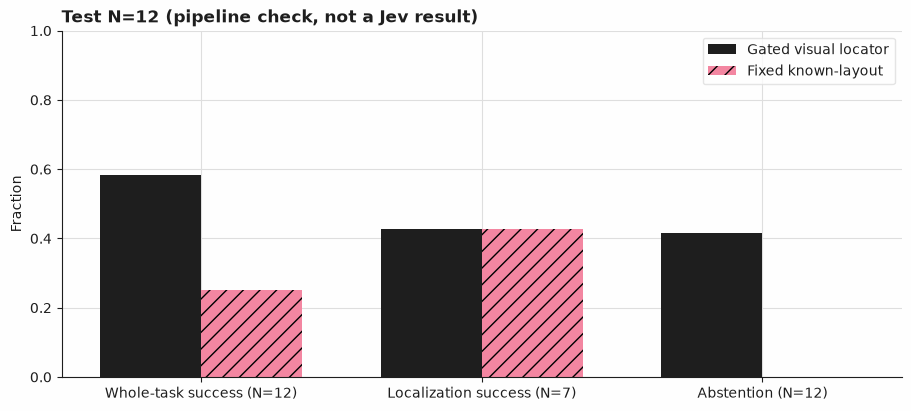

In [9]:
if reportable:
    plotted = {
        name: [result["task_success"], result["localization_success"], result["abstention"]]
        for name, result in metrics.items()
    }
    chart_denominators = [
        len(test),
        metrics["gated visual locator"]["actionable_present"],
        len(test),
    ]
    for name, values in plotted.items():
        print(
            f"{name}: {[round(value, 4) for value in values]}; denominators={chart_denominators}{check}{record_note}"
        )
    fig = Figure(figsize=(9, 4), layout="constrained")
    ax = fig.subplots()
    positions = [0, 1, 2]
    ax.bar(
        [x - 0.18 for x in positions],
        plotted["gated visual locator"],
        width=0.36,
        label="Gated visual locator",
        color="#1E1E1E",
    )
    ax.bar(
        [x + 0.18 for x in positions],
        plotted["fixed known-layout"],
        width=0.36,
        label="Fixed known-layout",
        color="#F386A1",
        hatch="//",
    )
    ax.set_xticks(
        positions,
        [
            f"Whole-task success (N={len(test)})",
            f"Localization success (N={chart_denominators[1]})",
            f"Abstention (N={len(test)})",
        ],
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("Fraction")
    ax.set_title(f"Test N={len(test)}{check}")
    ax.legend()
    display(fig)

### Inspect an accepted error

In the committed synthetic run, `t04` points at the card heading while the named button is lower down. Both stage probabilities and Box confidence pass. The cell finds an actual accepted localization error in the current run, or says that none was found. Gold rectangles appear here only for evaluation, after prediction. This accepted mistake illustrates that a gate checks reported certainty, not ground truth.

Example t04; predicted: {'top': 0.23958333333333334, 'bottom': 0.3229166666666667, 'left': 0.10546875, 'right': 0.55078125}; gold: [{'top': 0.6145833333333334, 'bottom': 0.7291666666666666, 'left': 0.12890625, 'right': 0.44140625}] (pipeline check, not a Jev result)


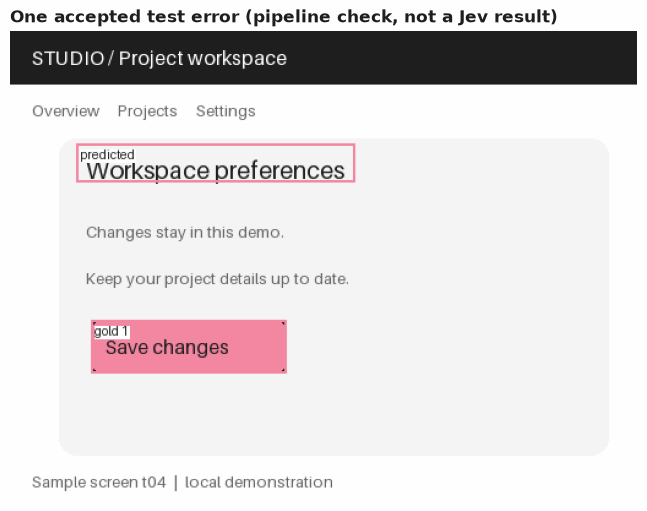

In [10]:
if reportable:
    wrong_examples = [
        e
        for e in test
        if outcomes[e.id].status == "located" and not helpers.success(outcomes[e.id], labels[e.id])
    ]
    if wrong_examples:
        wrong_example = wrong_examples[0]
        wrong = outcomes[wrong_example.id]
        gold_boxes = labels[wrong_example.id]["boxes"]
        print(
            f"Example {wrong_example.id}; predicted: {wrong.box}; gold: {gold_boxes}{check}{record_note}"
        )
        boxes = {
            "predicted": wrong.box,
            **{f"gold {i + 1}": box for i, box in enumerate(gold_boxes)},
        }
        with Image.open(recipe_dir / wrong_example.fields["image"]) as source:
            marked = draw_boxes(source, boxes)
        fig = Figure(figsize=(7, 5), layout="constrained")
        ax = fig.subplots()
        ax.imshow(marked)
        ax.set_title(f"One accepted test error{check}")
        ax.axis("off")
        display(fig)
    else:
        print(
            f"No accepted localization error in this test sample; split N={len(test)}{check}{record_note}"
        )

## What was and was not measured

The cell below states the mode, sample sizes, and the returned model and capture date when applicable. All authored answers are synthetic, including the wrong ones. No live inference was measured for the committed recipe. Latency, input tokens, output tokens and cost are `null`, meaning unmeasured, not zero. Reported numbers describe only these written-for-the-recipe images and responses.

A direct live run remains exploratory and its test aggregates are withheld. To report a model result, deliberately record responses and identify the returned model, capture date and held-out N. A recording of different responses can change which dependent Box requests are needed; missing replay requests must be recorded explicitly, never fabricated. Experimental visual capabilities and these synthetic screenshots provide no evidence of reliability on arbitrary websites.

In [11]:
print(
    f"Mode: {backend.mode}; validation N={len(validation)}, held-out test N={len(test)}, unscored demo N=2."
)
if backend.mode in ("synthetic", "scripted"):
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: validation={len(validation)}, held-out test={len(test)}, demo=2 (unscored).")
elif backend.mode == "recorded":
    print(
        f"Returned model: {backend.model}; capture dates: {', '.join(backend.recorded_dates)}; held-out N={len(test)}."
    )
else:
    returned_answers = [
        answer for seen in test_observations.values() for answer in seen.judgments.values()
    ]
    returned_answers.extend(
        seen.location for seen in test_observations.values() if seen.location is not None
    )
    returned_models = sorted(
        {
            answer.provenance.model
            for seen in test_observations.values()
            for answer in seen.judgments.values()
        }
    )
    print(
        f"Requested model: jev-1.14.0; returned models: {returned_models}; exploratory held-out N={len(test)}."
    )
    print("Unrecorded live values are not reportable model results.")
print(
    json.dumps({"latency_ms": None, "input_tokens": None, "output_tokens": None, "cost_usd": None})
)

Mode: synthetic; validation N=10, held-out test N=12, unscored demo N=2.
Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: validation=10, held-out test=12, demo=2 (unscored).
{"latency_ms": null, "input_tokens": null, "output_tokens": null, "cost_usd": null}


## Next steps

Try new screenshot themes, viewport sizes, partial occlusion, and labels with similar wording. Keep validation and test images distinct, freeze the policy before opening test, and retain absent and duplicate targets. A real browser integration would need additional exact checks for page identity, freshness and permitted actions; those checks are beyond this simulation.

Continue with [tool outcome verification](../29-tool-outcome-verification/) to check whether an attempted tool step achieved its purpose, or [abstention and review queues](../38-abstention-and-review-queues/) to examine the cost of deferring uncertain results. The image and localization interfaces are documented in [S09](https://docs.typesafe.ai/images) and [S10](https://docs.typesafe.ai/primitives/box).